# Advanced Algorithms: Streaming and Sketching Algorithms

> **Prerequisite:** [`dsa/04` Hashing](../dsa/04_hashing.ipynb) (hash functions, Bloom filters) and [`advanced_algorithms/01` Amortized and randomized algorithms](01_amortized_and_randomized_algorithms.ipynb) (universal hashing, Monte Carlo algorithms).
>
> **Who is this for:** you can write Python loops and dictionaries and you have heard of hash functions. You want to know how systems count, sample and deduplicate billions of events with a few kilobytes of memory. It is also for students taking a "Big Data Algorithms" / "Mining Massive Datasets" course, and for interviews ("count unique visitors without storing them").
>
> **What you will learn:**
> - The **streaming model** (one pass, sublinear memory) and what an $(\varepsilon, \delta)$ guarantee means
> - **Reservoir sampling** (Algorithm R, plus a weighted variant), checked with a chi-square uniformity test
> - **Heavy hitters**: Misra–Gries and Space-Saving top-$k$
> - **Count-Min sketch** from scratch: error versus width and depth
> - **HyperLogLog** from scratch: counting distinct items with 1–16 KB, error versus number of registers
> - **MinHash + LSH banding** for near-duplicate detection, with the famous S-curve
> - **Quantile sketches** (a log-bucket sketch and a simplified KLL) for streaming p95/p99 latency
> - **Sliding-window counting** with exponential histograms (DGIM)
> - Industry case: deduplicating a fine-tuning corpus, and streaming unique-user counts for a dashboard
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [NumPy](../../02_Data_Analysis/02_numpy.ipynb); probability basics (expected value, independence), see the [probability notebook](../../14_Mathematics/03_probability.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about one to two minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets* (ch. 3 and 4) and Cormode & Yi, *Small Summaries for Big Data*.

## Explained simply

Some data arrives so fast and in such huge amounts that you cannot store it all: every click on a website, every search, every request to an AI model. **Streaming algorithms** look at each item once, as it flies past, and keep only a tiny "summary" (called a **sketch**) in memory. From that summary they can still answer useful questions, such as "how many different visitors came today?" or "which songs are the most played?", with a small, known error. It is like a teacher who estimates how full the school hall is by counting one row and multiplying, instead of counting every student. Or like a bouncer who remembers "the busiest regulars" without writing down every face that walks in. The trade-off is simple: you give up a tiny bit of accuracy and save a huge amount of memory and time.

**Tiny example.** You want a fair random sample of 1 song from a playlist, but the songs are played one at a time and you do not know how many there will be. Keep song 1. When song 2 plays, switch to it with chance 1/2. When song 3 plays, switch with chance 1/3, and so on. After 4 songs, each of the 4 has exactly a 1-in-4 chance of being the one you kept: for song 1 that is $1 \times \tfrac12 \times \tfrac23 \times \tfrac34 = \tfrac14$. You only ever remembered one song.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Sketch | a tiny summary of a huge stream that answers questions approximately | website analytics, monitoring dashboards |
| HyperLogLog | counts how many *different* things you saw using a few kilobytes | "unique visitors today", Redis, BigQuery |
| MinHash + LSH | quickly finds documents that are almost copies of each other | cleaning duplicate text out of LLM training data |

### How this notebook is different from `dsa/04`
[`dsa/04`](../dsa/04_hashing.ipynb) builds hash tables and the **Bloom filter**, which answers "have I seen this item?". Here we use hashing to answer *other* questions about a stream (how many distinct items, which items are frequent, what is the 99th percentile, which documents are near-duplicates), always with memory far smaller than the data. We do not repeat the Bloom filter; it appears in the summary table.

## Table of contents
0. Setup: reproducible hash functions
1. The streaming model
2. Reservoir sampling
3. Heavy hitters: Misra–Gries and Space-Saving
4. Count-Min sketch
5. HyperLogLog: counting distinct items
6. MinHash and locality-sensitive hashing (LSH)
7. Quantile sketches for p95/p99 latency
8. Sliding windows: exponential histograms (DGIM)
9. Industry mini-case: corpus deduplication and unique-user dashboards
10. Summary table and how this connects to modern AI
11. Recap, practice problems, further reading

---
## 0. Setup: reproducible hash functions

> 💬 **In plain English:** we set up hash functions that give the same "random" answer every time, and a skewed test stream.

Sketches need **many independent-looking hash functions**. Two families are used below:

1. **Carter–Wegman universal hashing** on integers: $h_{a,b}(x) = ((a x + b) \bmod p) \bmod w$ with the prime $p = 2^{31} - 1$ and random $a \in [1, p-1]$, $b \in [0, p-1]$. For $x < p$ every product fits in a 64-bit integer, so NumPy can hash a million items at once.
2. **splitmix64**, a fast 64-bit "mixer" that scrambles an integer into 64 random-looking bits (used by HyperLogLog, which needs many bits per item).

Strings are first turned into integers with `zlib.crc32`, which gives the **same value in every run**.

> ⚠️ **Common mistake:** using Python's built-in `hash()` for strings in a sketch that is saved or shared between processes. Since Python 3.3, string hashes are **randomised per process** (unless `PYTHONHASHSEED` is set), so two workers would build incompatible sketches.

In [1]:
import math, random, sys, time, zlib, heapq, itertools
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

random.seed(42)
np.random.seed(42)
pd.set_option("display.width", 140)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})

P31 = (1 << 31) - 1                                   # Mersenne prime 2^31 - 1


def universal_family(k, rng):
    """k random (a, b) pairs for h(x) = ((a*x + b) mod p)."""
    a = rng.integers(1, P31, size=k, dtype=np.int64)
    b = rng.integers(0, P31, size=k, dtype=np.int64)
    return a, b


def splitmix64(x, seed=0):
    """Vectorised 64-bit mixer: uint64 array in, uint64 array out (multiplication wraps mod 2^64)."""
    offset = np.uint64(((seed + 1) * 0x9E3779B97F4A7C15) % 2**64)   # seed-dependent start, computed exactly in Python
    z = np.asarray(x, dtype=np.uint64) + offset
    z = (z ^ (z >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
    z = (z ^ (z >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
    return z ^ (z >> np.uint64(31))


def str_to_int(s):
    return zlib.crc32(s.encode()) % P31                # stable across runs, < p


CHECKS = Counter()
print("Python", sys.version.split()[0], "| numpy", np.__version__)
print("crc32('hello') is always", str_to_int("hello"), "| Python hash('hello') changes per process:", hash("hello") != 0)

Python 3.12.3 | numpy 2.4.6
crc32('hello') is always 907060870 | Python hash('hello') changes per process: True


**A test stream.** Real event streams (page views, search queries, API calls, tokens) are **skewed**: a few items are very common and most are rare. We simulate one with a **Zipf** distribution: the $r$-th most common item has frequency roughly proportional to $1/r^{s}$.

events: 200,000   distinct items: 10,060
top 5 items: [(1, 52737), (2, 21269), (3, 12696), (4, 8731), (5, 6483)]


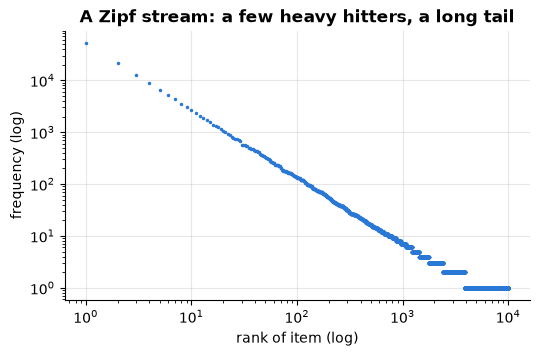

In [2]:
rng = np.random.default_rng(0)
N_EVENTS = 200_000
z = rng.zipf(1.3, 3 * N_EVENTS)
stream = z[z <= 50_000][:N_EVENTS].astype(np.int64)        # item ids 1..50,000, heavy-tailed (drop the extreme tail)
exact = Counter(stream.tolist())
print(f"events: {N_EVENTS:,}   distinct items: {len(exact):,}")
print("top 5 items:", exact.most_common(5))
fig, ax = plt.subplots(figsize=(6, 3.5))
freqs = np.array(sorted(exact.values(), reverse=True))
ax.loglog(np.arange(1, len(freqs) + 1), freqs, ".", ms=3)
ax.set(xlabel="rank of item (log)", ylabel="frequency (log)", title="A Zipf stream: a few heavy hitters, a long tail")
plt.show()

---
## 1. The streaming model

> 💬 **In plain English:** look at each item once, keep a tiny summary, and accept a small, guaranteed error.

**Intuition.** Imagine standing at a turnstile and clicking a counter for each person. You cannot ask people to walk back through again, and you cannot remember every face. Yet you want to answer: how many *different* people came? Who came most often? What was the median time between arrivals?

**Definition.** In the **data-stream model** the input is a sequence $a_1, a_2, \dots, a_N$ of items from a universe $U$. An algorithm:
- reads each item **once, in order** (one pass);
- uses memory **sublinear** in $N$ and $|U|$, ideally $O(\text{polylog}(N))$ or a constant chosen by the user;
- processes each item quickly (usually $O(1)$ or $O(\log)$ time);
- answers queries at any moment.

Most exact answers are impossible in sublinear space (e.g. exact distinct counting needs $\Omega(n)$ bits in the worst case), so we accept **approximate, randomised** answers with an **$(\varepsilon, \delta)$ guarantee**: the error is at most $\varepsilon$ (absolute or relative) with probability at least $1 - \delta$.

A **sketch** is a small data structure summarising the stream. Good sketches are **mergeable**: from sketch$(A)$ and sketch$(B)$ you can compute sketch$(A \cup B)$, so each server sketches its own shard and a coordinator merges them.

| question | exact needs | sketch | sketch memory |
|---|---|---|---|
| uniform sample of $k$ items | the whole stream | reservoir sampling | $O(k)$ |
| items with frequency $> N/k$ | a counter per distinct item | Misra–Gries / Space-Saving | $O(k)$ |
| frequency of any item | a counter per distinct item | Count-Min | $O(\frac{1}{\varepsilon}\log\frac{1}{\delta})$ |
| number of distinct items | a set of all items | HyperLogLog | $O(\frac{1}{\varepsilon^2})$ registers of $\log\log n$ bits |
| set similarity | both sets | MinHash | $O(\frac{1}{\varepsilon^2})$ per set |
| quantiles (p50, p99) | all values | KLL, t-digest, DDSketch | $O(\frac{1}{\varepsilon})$ (up to log factors) |
| count in the last $W$ items | the window | DGIM | $O(\log^2 W)$ bits |
| membership | a set | Bloom filter ([`dsa/04`](../dsa/04_hashing.ipynb)) | about 10 bits per item for 1% false positives |

---
## 2. Reservoir sampling

> 💬 **In plain English:** keep a fair random sample of a stream whose length you do not know.

**Problem.** Keep a uniformly random sample of $k$ items from a stream whose length $N$ is unknown in advance (logs of today, a crawl of unknown size). Every item must end up in the sample with probability exactly $k/N$.

**Algorithm R** (Vitter, 1985; attributed to Waterman):
1. Put the first $k$ items in the reservoir.
2. For item number $i > k$: with probability $k/i$, replace a uniformly random reservoir slot with it; otherwise discard it.

**Proof by induction (worked by hand).** Claim: after $i$ items, each of them is in the reservoir with probability $k/i$.
- Base: after $k$ items, each is in with probability $1 = k/k$.
- Step: item $i+1$ enters with probability $\frac{k}{i+1}$. An older item was in with probability $\frac{k}{i}$ and survives unless the newcomer enters *and* picks its slot: $\frac{k}{i+1}\cdot\frac{1}{k} = \frac{1}{i+1}$. So it is in with probability $\frac{k}{i}\left(1 - \frac{1}{i+1}\right) = \frac{k}{i}\cdot\frac{i}{i+1} = \frac{k}{i+1}$. ✓

Time $O(1)$ per item, memory $O(k)$. (Vitter's **Algorithm L** skips ahead geometrically and needs only $O(k(1 + \log(N/k)))$ random numbers.)

expected count per item = 5000
Algorithm R : min 4867, max 5139, chi-square p-value = 0.200
biased      : min 2262, max 9930, chi-square p-value = 0


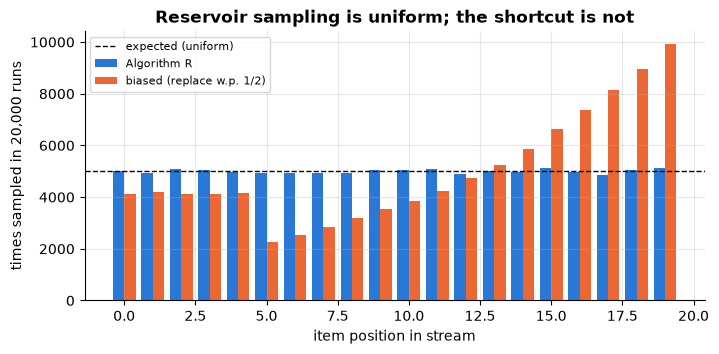

In [3]:
def reservoir_sample(stream, k, rng):
    """Algorithm R: uniform sample of k items from an iterable of unknown length."""
    reservoir = []
    for i, item in enumerate(stream, start=1):
        if i <= k:
            reservoir.append(item)               # fill the reservoir first
        else:
            j = rng.randrange(i)                 # uniform in [0, i)
            if j < k:                            # happens with probability k / i
                reservoir[j] = item              # ... and j is a uniform slot
    return reservoir


def biased_sample(stream, k, rng):
    """A tempting but WRONG version: replace a random slot with probability 1/2."""
    reservoir = []
    for i, item in enumerate(stream, start=1):
        if i <= k:
            reservoir.append(item)
        elif rng.random() < 0.5:
            reservoir[rng.randrange(k)] = item
    return reservoir


n_items, k, trials = 20, 5, 20_000
r = random.Random(1)
counts_R, counts_bad = Counter(), Counter()
for _ in range(trials):
    counts_R.update(reservoir_sample(range(n_items), k, r))
    counts_bad.update(biased_sample(range(n_items), k, r))
expected = trials * k / n_items
obs_R = np.array([counts_R[i] for i in range(n_items)])
obs_bad = np.array([counts_bad[i] for i in range(n_items)])
p_R = stats.chisquare(obs_R).pvalue
p_bad = stats.chisquare(obs_bad).pvalue
print(f"expected count per item = {expected:.0f}")
print(f"Algorithm R : min {obs_R.min()}, max {obs_R.max()}, chi-square p-value = {p_R:.3f}")
print(f"biased      : min {obs_bad.min()}, max {obs_bad.max()}, chi-square p-value = {p_bad:.3g}")
assert p_R > 0.001 and p_bad < 1e-6

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(np.arange(n_items) - 0.2, obs_R, width=0.4, label="Algorithm R")
ax.bar(np.arange(n_items) + 0.2, obs_bad, width=0.4, label="biased (replace w.p. 1/2)")
ax.axhline(expected, color="black", ls="--", lw=1, label="expected (uniform)")
ax.set(xlabel="item position in stream", ylabel=f"times sampled in {trials:,} runs", title="Reservoir sampling is uniform; the shortcut is not")
ax.legend(fontsize=8); plt.show()

**What just happened?** Over 20,000 runs each of the 20 items was picked close to the expected 5,000 times by Algorithm R, and the **chi-square goodness-of-fit test** (null hypothesis: uniform) does not reject (p-value printed above). The "replace with probability 1/2" shortcut keeps mostly the last few items: its p-value is essentially 0.

**Weighted reservoir sampling (A-Res, Efraimidis & Spirakis, 2006).** To sample with probability proportional to a weight $w_i$ (e.g. sample training examples by importance), give each item the key $u_i^{1/w_i}$ with $u_i \sim U(0,1)$ and keep the $k$ items with the **largest** keys using a min-heap. For $k = 1$ the chance of picking item $i$ is exactly $w_i / \sum_j w_j$.

In [4]:
def weighted_reservoir(stream_with_weights, k, rng):
    heap = []                                        # min-heap of (key, item): smallest key is evicted first
    for item, w in stream_with_weights:
        key = rng.random() ** (1.0 / w)
        if len(heap) < k:
            heapq.heappush(heap, (key, item))
        elif key > heap[0][0]:
            heapq.heapreplace(heap, (key, item))
    return [item for _, item in heap]


weights = {"a": 1, "b": 2, "c": 3, "d": 4}
r = random.Random(2)
picks = Counter(weighted_reservoir(weights.items(), 1, r)[0] for _ in range(40_000))
table = pd.DataFrame({"weight": weights, "theory": {x: w / 10 for x, w in weights.items()},
                      "observed": {x: picks[x] / 40_000 for x in weights}})
print(table.round(4))
assert np.allclose(table.theory, table.observed, atol=0.01)

   weight  theory  observed
a       1     0.1    0.1007
b       2     0.2    0.2006
c       3     0.3    0.2987
d       4     0.4    0.4000


**What just happened?** With $k = 1$ the observed pick rates match $w_i/\sum w = 0.1, 0.2, 0.3, 0.4$ to about two decimals. (For $k > 1$, A-Res samples *without replacement* in proportion to weight, so inclusion probabilities are not exactly $k w_i / \sum w$; that is expected, not a bug.)

> 🎓 **Exam / interview tip:** "Pick a random line from a huge file in one pass with $O(1)$ memory" is reservoir sampling with $k = 1$: keep line $i$ with probability $1/i$. Be ready to prove it by induction as above.

---
## 3. Heavy hitters: Misra–Gries and Space-Saving

> 💬 **In plain English:** find the most frequent items while keeping only a handful of counters.

**Problem.** Find the items that occur more than $N/k$ times (the **heavy hitters**: trending hashtags, the IPs causing most traffic, the most frequent queries to cache).

**Misra–Gries (1982)** keeps at most $k$ counters:
- if the item has a counter, increment it;
- else if fewer than $k$ counters exist, create one with count 1;
- else **decrement every counter** by 1 and delete those that reach 0 (the new item is "cancelled" together with $k$ others).

**Guarantee:** for every item, $f(x) - \frac{N}{k+1} \le \hat f(x) \le f(x)$. *Why:* each decrement step removes $k+1$ occurrences in total (one from each of the $k$ counters plus the new item), so there are at most $N/(k+1)$ such steps, and each step lowers any single counter by at most 1. So every item with $f(x) > N/(k+1)$ survives.

**Space-Saving (Metwally, Agrawal & El Abbadi, 2005)** also keeps $k$ counters, but when they are full it **replaces the item with the smallest count** $m$ and gives the newcomer count $m + 1$. It **overestimates**: $f(x) \le \hat f(x) \le f(x) + \min$, and $\min \le N/k$. It is the usual choice for "top-$k$" in practice.

Small trace of Misra–Gries with $k = 2$ on `a b a c a b d a`:

| item | counters after | note |
|---|---|---|
| a | {a:1} | |
| b | {a:1, b:1} | |
| a | {a:2, b:1} | |
| c | {a:1} | full: decrement all, b reaches 0 |
| a | {a:2} | |
| b | {a:2, b:1} | |
| d | {a:1} | decrement all |
| a | {a:2} | true $f(a) = 4$; estimate 2 $\ge 4 - 8/3$ ✓ |

In [5]:
def misra_gries(stream, k):
    counters = {}
    for x in stream:
        if x in counters:
            counters[x] += 1
        elif len(counters) < k:
            counters[x] = 1
        else:                                         # cancel x together with one occurrence of every counter
            for key in list(counters):
                counters[key] -= 1
                if counters[key] == 0:
                    del counters[key]
    return counters


def space_saving(stream, k):
    counts, errors = {}, {}
    for x in stream:
        if x in counts:
            counts[x] += 1
        elif len(counts) < k:
            counts[x], errors[x] = 1, 0
        else:
            victim = min(counts, key=counts.get)      # O(k) here; a "stream summary" list makes it O(1)
            m = counts.pop(victim); errors.pop(victim)
            counts[x], errors[x] = m + 1, m           # newcomer inherits the minimum (possible overestimate)
    return counts, errors


print("trace example:", misra_gries("abacabda", 2))
sub = stream[:60_000].tolist()                        # pure-Python loops: use 60k events
N = len(sub)
true = Counter(sub)
for k in [20, 100]:
    mg = misra_gries(sub, k)
    ss, err = space_saving(sub, k)
    for x, f in true.items():                         # check the guarantees for EVERY item
        assert f - N / (k + 1) <= mg.get(x, 0) <= f
        if x in ss:
            assert f <= ss[x] <= f + err[x] and err[x] <= N / k
    CHECKS["Misra-Gries bound"] += len(true); CHECKS["Space-Saving bound"] += len(true)
    top_true = [x for x, _ in true.most_common(10)]
    top_ss = [x for x, _ in sorted(ss.items(), key=lambda t: -t[1])[:10]]
    print(f"k = {k:3d}: N/(k+1) = {N / (k + 1):7.1f}; true top-10 found by Space-Saving: {len(set(top_true) & set(top_ss))}/10")
mg = misra_gries(sub, 20); ss, err = space_saving(sub, 20)
df = pd.DataFrame([{"item": x, "true f": f, "Misra-Gries (under)": mg.get(x, 0), "Space-Saving (over)": ss.get(x, None)}
                   for x, f in true.most_common(6)])
print(df.to_string(index=False))

trace example: {'a': 2}


k =  20: N/(k+1) =  2857.1; true top-10 found by Space-Saving: 6/10


k = 100: N/(k+1) =   594.1; true top-10 found by Space-Saving: 10/10
 item  true f  Misra-Gries (under)  Space-Saving (over)
    1   15892                14052                15892
    2    6278                 4438                 6278
    3    3803                 1963                 3803
    4    2617                  777                 2617
    5    1958                  126                 1976
    6    1532                    2                 1964


**What just happened?** The error bounds held for *every* item in the stream (both algorithms, $k = 20$ and $k = 100$). Misra–Gries **underestimates** and Space-Saving **overestimates**, by at most $N/(k+1)$ and $N/k$ respectively, using only $k$ counters instead of one per distinct item. With 100 counters Space-Saving recovered the exact true top-10; with only 20 counters it found 6 of the 10 (ranks 8–10 are close in frequency, so the overestimates can reorder them).

**Complexity:** Misra–Gries is $O(1)$ amortised per item (each decrement step can be charged to earlier increments), memory $O(k)$. Space-Saving is $O(1)$ per item with the "stream summary" linked-list structure; our version uses $O(k)$ for the `min`.

---
## 4. Count-Min sketch

> 💬 **In plain English:** estimate how often any item appeared using a small grid of counters.

**Intuition.** Keep a small table of counters with $d$ rows and $w$ columns. Each row has its own hash function. To add item $x$, increment one counter in each row: $C[j, h_j(x)] \mathrel{+}= 1$. Different items can **collide** in a counter, which can only *inflate* it. So to estimate $f(x)$, look at its $d$ counters and take the **minimum**, the one least polluted by collisions.

```
            w columns
row 1:  [ 0  3  0  7  1  0 ]   <- h1(x) = 3  -> 7
row 2:  [ 2  0  9  0  0  1 ]   <- h2(x) = 2  -> 9
row 3:  [ 0  0  0  1  8  0 ]   <- h3(x) = 4  -> 8      estimate = min(7, 9, 8) = 7
```

**Guarantee (Cormode & Muthukrishnan, 2005).** With $w = \lceil e/\varepsilon \rceil$ and $d = \lceil \ln(1/\delta) \rceil$ and pairwise-independent hashes:
$$f(x) \le \hat f(x) \quad\text{always,}\qquad \hat f(x) \le f(x) + \varepsilon N \quad\text{with probability} \ge 1 - \delta.$$
*Why:* in one row the expected collision mass is at most $N/w = \varepsilon N / e$; by Markov's inequality it exceeds $\varepsilon N$ with probability at most $1/e$; all $d$ independent rows fail with probability at most $e^{-d} \le \delta$.

Memory $O(wd) = O(\frac{1}{\varepsilon}\log\frac{1}{\delta})$, update and query time $O(d)$. Two sketches with the same hashes **merge** by adding their tables.

In [6]:
class CountMin:
    def __init__(self, width, depth, seed=0):
        self.w, self.d = width, depth
        self.a, self.b = universal_family(depth, np.random.default_rng(seed))
        self.table = np.zeros((depth, width), dtype=np.int64)

    def _cols(self, x):
        x = np.asarray(x, dtype=np.int64)                       # items are ints < 2^31
        return ((self.a[:, None] * x[None, :] + self.b[:, None]) % P31) % self.w   # shape (d, len(x))

    def add(self, items):
        cols = self._cols(items)
        for j in range(self.d):
            np.add.at(self.table[j], cols[j], 1)               # handles repeated columns correctly

    def query(self, items):
        cols = self._cols(items)
        return self.table[np.arange(self.d)[:, None], cols].min(axis=0)

    def merge(self, other):
        assert (self.a == other.a).all() and (self.b == other.b).all(), "merge needs identical hash functions"
        self.table += other.table


eps, delta = 0.001, 0.01
w, d = math.ceil(math.e / eps), math.ceil(math.log(1 / delta))
cm = CountMin(w, d)
cm.add(stream)
items = np.array(list(exact.keys()))
truth = np.array([exact[x] for x in items])
est = cm.query(items)
err = est - truth
assert (err >= 0).all()                                         # never underestimates
frac_ok = np.mean(err <= eps * N_EVENTS)
print(f"w = {w}, d = {d}: {w * d:,} counters for {len(items):,} distinct items")
print(f"max error = {err.max()}, allowed eps*N = {eps * N_EVENTS:.0f}; fraction within bound = {frac_ok:.4f} (guarantee >= {1 - delta})")

# mergeability: sketch two halves separately, then merge
c1, c2 = CountMin(w, d), CountMin(w, d)
c1.add(stream[: N_EVENTS // 2]); c2.add(stream[N_EVENTS // 2:]); c1.merge(c2)
assert (c1.table == cm.table).all()
print("merged sketch of two halves == sketch of the whole stream")

w = 2719, d = 5: 13,595 counters for 10,060 distinct items
max error = 22, allowed eps*N = 200; fraction within bound = 1.0000 (guarantee >= 0.99)


merged sketch of two halves == sketch of the whole stream


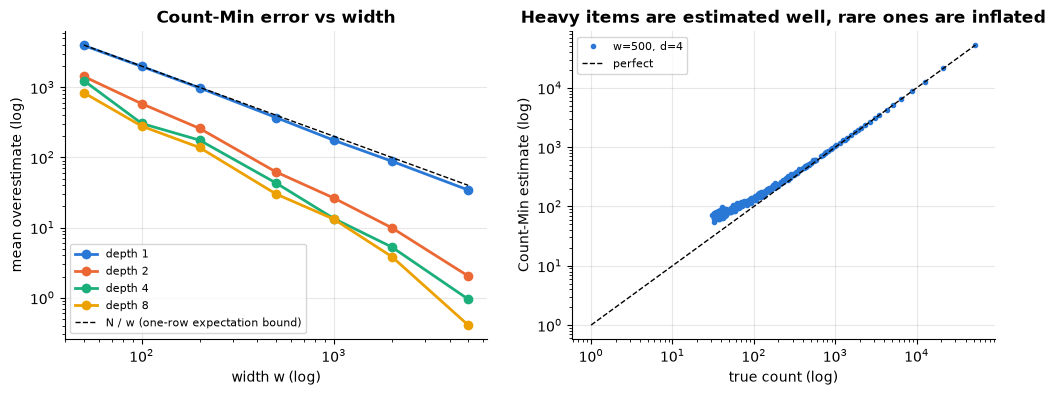

depth       1       2       4      8
width                               
50     3941.6  1425.7  1243.0  835.1
100    1979.9   583.1   304.9  279.4
200     981.5   259.5   176.3  138.4
500     370.5    62.0    43.2   30.1
1000    175.5    26.3    13.4   13.2
2000     88.4     9.9     5.3    3.9
5000     34.3     2.0     1.0    0.4


In [7]:
rows = []
for width in [50, 100, 200, 500, 1000, 2000, 5000]:
    for depth in [1, 2, 4, 8]:
        s = CountMin(width, depth, seed=width * 10 + depth)
        s.add(stream)
        e = s.query(items) - truth
        rows.append({"width": width, "depth": depth, "mean error": e.mean(), "p99 error": np.percentile(e, 99)})
R = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for depth, g in R.groupby("depth"):
    axes[0].loglog(g.width, g["mean error"], "o-", label=f"depth {depth}")
axes[0].loglog(R.width.unique(), N_EVENTS / R.width.unique(), "k--", lw=1, label="N / w (one-row expectation bound)")
axes[0].set(xlabel="width w (log)", ylabel="mean overestimate (log)", title="Count-Min error vs width"); axes[0].legend(fontsize=8)
top = exact.most_common(300)
s = CountMin(500, 4); s.add(stream)
axes[1].loglog([f for _, f in top], s.query(np.array([x for x, _ in top])), ".", label="w=500, d=4")
axes[1].loglog([1, top[0][1]], [1, top[0][1]], "k--", lw=1, label="perfect")
axes[1].set(xlabel="true count (log)", ylabel="Count-Min estimate (log)", title="Heavy items are estimated well, rare ones are inflated")
axes[1].legend(fontsize=8); plt.show()
print(R.pivot(index="width", columns="depth", values="mean error").round(1))

**What just happened?**
- With $\varepsilon = 0.001$, $\delta = 0.01$ we used $2{,}719 \times 5 = 13{,}595$ counters and **every** item's error was within $\varepsilon N = 200$, comfortably beating the promised 99%.
- Error falls roughly like $1/w$ (left plot), and extra rows help a lot at first: taking the minimum of independent rows filters out unlucky collisions.
- Relative error is tiny for heavy items and large for rare ones (right plot): a rare item that shares counters with a heavy one looks bigger than it is. Count-Min is therefore good for "how often does this *frequent* thing happen?" and for heavy-hitter detection, not for exact counts of rare items.

> ⚠️ **Common mistake:** taking the **mean** of the $d$ counters instead of the minimum. Collisions only add, so the minimum is the best estimate. (The **Count sketch** of Charikar, Chen & Farach-Colton uses random $\pm1$ signs and the **median** instead, giving unbiased estimates that also work with deletions.)

**Connection:** the **hashing trick** for features (`sklearn.feature_extraction.FeatureHasher`) is a one-row Count sketch with signs: it maps millions of sparse features into a fixed-size vector.

---
## 5. HyperLogLog: counting distinct items

> 💬 **In plain English:** count how many different items you saw by looking at rare patterns in their hashes.

**Intuition.** Flip coins until you get heads. If someone tells you their longest run of tails *before* the first heads was 10, you would guess they flipped many sequences (about $2^{10}$), because a run that long is rare. Hash every item to random bits and record the **maximum number of leading zeros** seen: with $n$ distinct items that maximum is about $\log_2 n$. Duplicates hash to the same bits, so they do not change the maximum: we are counting **distinct** items.

One maximum is very noisy, so **HyperLogLog** (Flajolet, Fusy, Gandouet & Meunier, 2007) splits the items into $m = 2^p$ buckets using the first $p$ bits of the hash, keeps one maximum ("register") per bucket, and combines them with a **harmonic mean**:
$$E = \alpha_m\, m^2 \Big(\sum_{j=1}^{m} 2^{-M_j}\Big)^{-1}, \qquad \alpha_m \approx \frac{0.7213}{1 + 1.079/m}.$$
For small counts (many empty registers $V$) it switches to **linear counting**: $E = m \ln(m / V)$.

**Guarantee:** standard error about $1.04/\sqrt{m}$. With $m = 2^{14} = 16{,}384$ registers of 6 bits (about 12 KB) the error is about **0.8%**, whether you count a thousand or a billion items. Registers merge by element-wise **max**.

Worked example with $p = 2$ (4 registers) and 8-bit hashes:

| hash bits | register (first 2 bits) | rest | leading zeros + 1 |
|---|---|---|---|
| `01`\|`001011` | 1 | `001011` | 3 |
| `11`\|`100000` | 3 | `100000` | 1 |
| `01`\|`000110` | 1 | `000110` | 4 → register 1 becomes max(3, 4) = 4 |

In [8]:
class HyperLogLog:
    def __init__(self, p=12, seed=0):
        self.p, self.m, self.seed = p, 1 << p, seed
        self.reg = np.zeros(self.m, dtype=np.uint8)            # each register needs only 6 bits

    def add(self, items):
        h = splitmix64(np.asarray(items, dtype=np.uint64), self.seed)
        idx = (h >> np.uint64(64 - self.p)).astype(np.int64)    # first p bits choose the register
        rest = h & np.uint64((1 << (64 - self.p)) - 1)          # remaining 64 - p bits
        bitlen = np.zeros(len(h), dtype=np.int64)               # exact bit length of rest (vectorised)
        for k in range(64 - self.p):
            bitlen += (rest >> np.uint64(k)) > 0
        rank = (64 - self.p) - bitlen + 1                       # leading zeros + 1
        np.maximum.at(self.reg, idx, rank.astype(np.uint8))

    def count(self):
        m = self.m
        alpha = 0.7213 / (1 + 1.079 / m)
        E = alpha * m * m / np.sum(2.0 ** -self.reg.astype(float))
        V = np.count_nonzero(self.reg == 0)
        if E <= 2.5 * m and V > 0:                              # small-range correction: linear counting
            E = m * math.log(m / V)
        return E

    def merge(self, other):
        assert self.p == other.p and self.seed == other.seed
        self.reg = np.maximum(self.reg, other.reg)


h = HyperLogLog(p=12)
h.add(stream)
print(f"distinct items: true = {len(exact):,}, HLL estimate = {h.count():,.0f} "
      f"(error {abs(h.count() - len(exact)) / len(exact):.2%}), memory = {h.m} registers = {h.m * 6 // 8:,} bytes")

distinct items: true = 10,060, HLL estimate = 10,383 (error 3.21%), memory = 4096 registers = 3,072 bytes


 p  registers m  n distinct  measured std error  theory 1.04/sqrt(m)
 4           16        1000              0.3269               0.2600
 4           16      100000              0.2840               0.2600
 6           64        1000              0.0877               0.1300
 6           64      100000              0.1704               0.1300
 8          256        1000              0.0466               0.0650
 8          256      100000              0.0466               0.0650
10         1024        1000              0.0304               0.0325
10         1024      100000              0.0359               0.0325
12         4096        1000              0.0133               0.0162
12         4096      100000              0.0175               0.0162
14        16384        1000              0.0048               0.0081
14        16384      100000              0.0075               0.0081


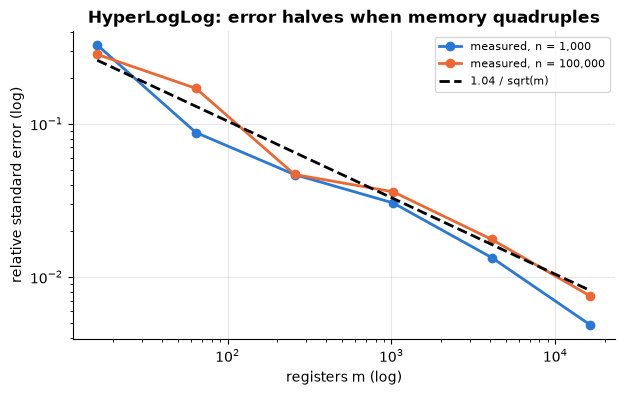

In [9]:
rng = np.random.default_rng(3)
rows = []
for p in range(4, 15, 2):
    for n_distinct in [1_000, 100_000]:
        errs = []
        for trial in range(20):
            hh = HyperLogLog(p=p, seed=trial)
            hh.add(rng.integers(0, 2**62, size=n_distinct, dtype=np.int64))   # ids; collisions negligible
            errs.append((hh.count() - n_distinct) / n_distinct)
        rows.append({"p": p, "registers m": 2 ** p, "n distinct": n_distinct, "measured std error": np.std(errs),
                     "theory 1.04/sqrt(m)": 1.04 / math.sqrt(2 ** p)})
H = pd.DataFrame(rows)
print(H.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
for n_distinct, g in H.groupby("n distinct"):
    ax.loglog(g["registers m"], g["measured std error"], "o-", label=f"measured, n = {n_distinct:,}")
ax.loglog(H["registers m"].unique(), 1.04 / np.sqrt(H["registers m"].unique()), "k--", label="1.04 / sqrt(m)")
ax.set(xlabel="registers m (log)", ylabel="relative standard error (log)", title="HyperLogLog: error halves when memory quadruples")
ax.legend(fontsize=8); plt.show()

**What just happened?** On our Zipf stream (200,000 events, the number of distinct items printed above) 4,096 registers (3 KB) estimated the distinct count within a few percent. Across 20 random trials per setting, the measured relative standard error follows $1.04/\sqrt{m}$ for both 1,000 and 100,000 distinct items (20 trials give a noisy estimate of a standard deviation, so expect deviations of ±30% from the dashed line). When the count is small compared with $m$ (1,000 items, $m = 16{,}384$), the linear-counting correction is even more accurate than the formula. Halving the error costs **4×** memory: that is the $1/\varepsilon^2$ in the memory bound.

> 🎓 **Exam / interview tip:** "Count unique visitors per day across 100 servers" → each server keeps an HLL; the dashboard **merges** them with an element-wise max. You cannot add daily unique counts to get weekly uniques (a returning visitor would be counted twice), but you *can* merge daily HLLs. Redis (`PFADD`/`PFCOUNT`) and BigQuery (`APPROX_COUNT_DISTINCT`, HLL++) work this way.

---
## 6. MinHash and locality-sensitive hashing (LSH)

> 💬 **In plain English:** find near-copies of documents without comparing every pair.

**Problem.** Among a million web pages (or training documents) find the pairs that are **near-duplicates**. Comparing all pairs is $\binom{10^6}{2} \approx 5 \times 10^{11}$ comparisons: too many.

**Step 1: documents → sets.** Represent each document by its set of **shingles** (here, word 3-grams). Similarity = **Jaccard similarity** $J(A, B) = \frac{|A \cap B|}{|A \cup B|}$.

**Step 2: sets → short signatures (MinHash).** Apply a random hash $h$ to every shingle and keep the minimum. **Key fact (Broder, 1997):**
$$\Pr[\min h(A) = \min h(B)] = J(A, B).$$
*Why:* the element of $A \cup B$ with the smallest hash is equally likely to be any of them; the two minimums agree exactly when that element lies in $A \cap B$. With $k$ hash functions, the fraction of agreeing positions estimates $J$ with standard error about $\sqrt{J(1-J)/k}$.

**Step 3: signatures → candidate pairs (LSH banding).** Cut each $k$-long signature into $b$ **bands** of $r$ rows ($k = br$). Hash each band to a bucket; two documents become a **candidate pair** if they share a bucket in **at least one** band. If $J(A,B) = s$:
$$\Pr[\text{candidate}] = 1 - (1 - s^r)^b,$$
an **S-curve** with a threshold near $(1/b)^{1/r}$: pairs above it are almost always caught, pairs below it almost never. Only candidates are compared exactly.

In [10]:
VOCAB = [f"w{i}" for i in range(3000)]


def make_doc(rng, length):
    return [VOCAB[i] for i in rng.integers(0, len(VOCAB), length)]


def mutate(doc, rate, rng):
    """Edit a fraction `rate` of positions: substitute, delete or insert a word."""
    out = []
    for word in doc:
        u = rng.random()
        if u < rate / 3:
            out.append(VOCAB[rng.integers(len(VOCAB))])       # substitute
        elif u < 2 * rate / 3:
            continue                                         # delete
        elif u < rate:
            out += [word, VOCAB[rng.integers(len(VOCAB))]]   # insert after
        else:
            out.append(word)
    return out


def shingles(doc, n=3):
    return {str_to_int(" ".join(doc[i:i + n])) for i in range(len(doc) - n + 1)}


def jaccard(A, B):
    return len(A & B) / len(A | B) if A | B else 1.0


class MinHasher:
    def __init__(self, k=128, seed=0):
        self.k = k
        self.a, self.b = universal_family(k, np.random.default_rng(seed))

    def signature(self, shingle_set):
        s = np.fromiter(shingle_set, dtype=np.int64)
        return ((self.a[:, None] * s[None, :] + self.b[:, None]) % P31).min(axis=1)   # k minimums


rng = np.random.default_rng(5)
mh = MinHasher(k=128)
pairs = []
for rate in np.linspace(0, 1.0, 300):                     # pairs with every level of similarity
    base = make_doc(rng, 120)
    A, B = shingles(base), shingles(mutate(base, rate, rng))
    sa, sb = mh.signature(A), mh.signature(B)
    pairs.append({"true J": jaccard(A, B), "MinHash est": np.mean(sa == sb), "sigA": sa, "sigB": sb})
Pdf = pd.DataFrame(pairs)
err = Pdf["MinHash est"] - Pdf["true J"]
print(f"MinHash (k=128) on {len(Pdf)} pairs: mean abs error = {err.abs().mean():.4f}, max abs error = {err.abs().max():.4f}"
      f" (theory: std <= 0.5/sqrt(128) = {0.5 / math.sqrt(128):.4f})")

MinHash (k=128) on 300 pairs: mean abs error = 0.0190, max abs error = 0.1082 (theory: std <= 0.5/sqrt(128) = 0.0442)


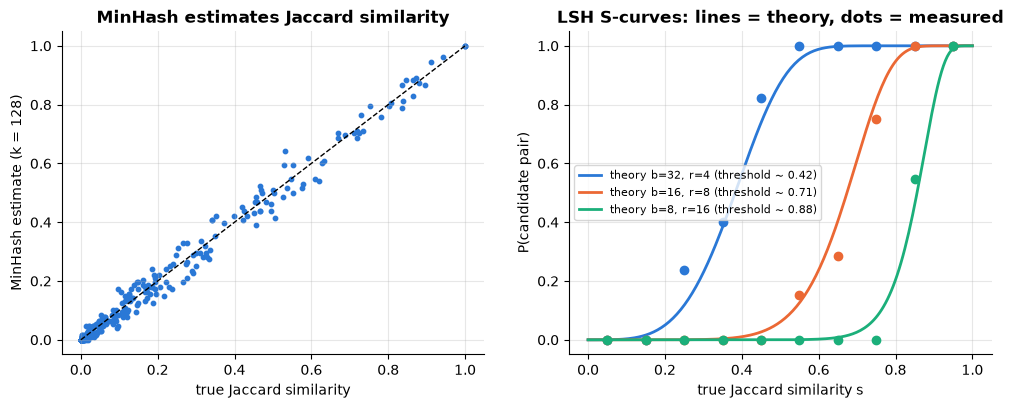

In [11]:
def lsh_candidate(sa, sb, b, r):
    """True if the two signatures agree on all r rows of at least one of the b bands."""
    return any(np.array_equal(sa[i * r:(i + 1) * r], sb[i * r:(i + 1) * r]) for i in range(b))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(Pdf["true J"], Pdf["MinHash est"], s=10)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="true Jaccard similarity", ylabel="MinHash estimate (k = 128)", title="MinHash estimates Jaccard similarity")
s_grid = np.linspace(0, 1, 200)
bins = np.linspace(0, 1, 11)
for (b, r), col in zip([(32, 4), (16, 8), (8, 16)], PALETTE):
    axes[1].plot(s_grid, 1 - (1 - s_grid ** r) ** b, color=col, label=f"theory b={b}, r={r} (threshold ~ {(1 / b) ** (1 / r):.2f})")
    cand = np.array([lsh_candidate(sa, sb, b, r) for sa, sb in zip(Pdf.sigA, Pdf.sigB)])
    which = np.digitize(Pdf["true J"], bins) - 1
    centres = [(bins[i] + bins[i + 1]) / 2 for i in range(10) if (which == i).any()]
    rates = [cand[which == i].mean() for i in range(10) if (which == i).any()]
    axes[1].plot(centres, rates, "o", color=col)
axes[1].set(xlabel="true Jaccard similarity s", ylabel="P(candidate pair)", title="LSH S-curves: lines = theory, dots = measured")
axes[1].legend(fontsize=8); plt.show()

**What just happened?** Left: MinHash estimates lie on the diagonal with the small scatter the theory predicts (printed above). Right: the measured candidate rates (dots) follow the theoretical S-curves (lines). Choosing $(b, r)$ moves the threshold: $b = 32, r = 4$ catches pairs above about 0.42 similarity; $b = 8, r = 16$ only catches pairs above about 0.88. More bands → more candidates (higher recall, more exact checks); more rows per band → stricter.

Now the full pipeline on a corpus: 400 documents of which 80 have a near-duplicate copy. We compare LSH with exact all-pairs comparison.

In [12]:
def exact_similar_pairs(shingle_sets, threshold):
    """Exact all-pairs Jaccard, vectorised: |A & B| for every pair from one sparse matrix product."""
    from scipy import sparse
    vocab = {s: i for i, s in enumerate(set().union(*shingle_sets))}
    rows = np.repeat(np.arange(len(shingle_sets)), [len(s) for s in shingle_sets])
    cols = np.fromiter((vocab[x] for s in shingle_sets for x in s), dtype=np.int64)
    X = sparse.csr_matrix((np.ones(len(cols)), (rows, cols)), shape=(len(shingle_sets), len(vocab)))
    inter = (X @ X.T).tocoo()                               # n x n intersections (the O(n^2) part)
    sizes = np.array([len(s) for s in shingle_sets])
    keep = inter.row < inter.col
    i, j, v = inter.row[keep], inter.col[keep], inter.data[keep]
    jac = v / (sizes[i] + sizes[j] - v)
    return {(int(a), int(b)) for a, b, jj in zip(i, j, jac) if jj >= threshold}


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        self.parent[self.find(a)] = self.find(b)


def lsh_near_duplicates(shingle_sets, threshold=0.5, k=128, b=32, r=4, seed=0):
    """Return (pairs with Jaccard >= threshold found via LSH, number of exact comparisons made)."""
    mh = MinHasher(k, seed)
    sigs = [mh.signature(s) for s in shingle_sets]
    buckets = defaultdict(list)
    for doc_id, sig in enumerate(sigs):
        for band in range(b):
            buckets[(band, sig[band * r:(band + 1) * r].tobytes())].append(doc_id)   # band contents -> bucket
    candidates = set()
    for ids in buckets.values():
        for i, j in itertools.combinations(ids, 2):
            candidates.add((min(i, j), max(i, j)))
    found = {(i, j) for i, j in candidates if jaccard(shingle_sets[i], shingle_sets[j]) >= threshold}
    return found, len(candidates)


def build_corpus(n_docs, n_dups, rng):
    docs = [make_doc(rng, int(rng.integers(80, 160))) for _ in range(n_docs - n_dups)]
    for i in rng.choice(len(docs), n_dups, replace=False):
        docs.append(mutate(docs[i], rng.uniform(0.02, 0.15), rng))    # a lightly edited copy
    return docs


rng = np.random.default_rng(11)
docs = build_corpus(400, 80, rng)
S = [shingles(d) for d in docs]
t0 = time.perf_counter()
exact_pairs = exact_similar_pairs(S, 0.5)
assert all(jaccard(S[i], S[j]) >= 0.5 for i, j in exact_pairs)          # spot-check with Python sets
t_exact = time.perf_counter() - t0
t0 = time.perf_counter()
found, n_cand = lsh_near_duplicates(S, threshold=0.5)
t_lsh = time.perf_counter() - t0
recall = len(found & exact_pairs) / len(exact_pairs)
print(f"exact all-pairs: {len(S) * (len(S) - 1) // 2:,} pairs scored, {len(exact_pairs)} near-duplicate pairs")
print(f"MinHash-LSH    : {n_cand:,} candidate comparisons, {len(found)} pairs found, recall = {recall:.3f}, "
      f"precision = {len(found & exact_pairs) / max(1, len(found)):.3f}")
missed = exact_pairs - found
print("similarity of missed pairs:", sorted(round(jaccard(S[i], S[j]), 3) for i, j in missed))

exact all-pairs: 79,800 pairs scored, 76 near-duplicate pairs
MinHash-LSH    : 76 candidate comparisons, 74 pairs found, recall = 0.974, precision = 1.000
similarity of missed pairs: [0.524, 0.538]


**What just happened?** LSH checked only 76 candidate pairs instead of all 79,800, and found 74 of the 76 true near-duplicate pairs (recall 97.4%; precision is 1 because every candidate is verified exactly). The two misses have similarity just above the 0.5 threshold, where the $b=32, r=4$ S-curve is about 0.87 rather than 1; adding bands (or lowering $r$) would catch them at the cost of more candidates. At 400 documents exact comparison is still affordable; at $10^6$ documents ($5 \times 10^{11}$ pairs) it is not, while the LSH cost grows roughly linearly with the number of documents.

> ⚠️ **Common mistake:** shingles that are too short. With single words (1-shingles), two unrelated English documents share "the", "of", "and" and look similar. Use word 3–5-grams or character 5–9-grams.

**Complexity:** MinHash signature $O(k \cdot |\text{shingles}|)$ per document; LSH bucketing $O(n b)$; plus the candidate checks. Compare $O(n^2)$ for all pairs.

---
## 7. Quantile sketches for p95/p99 latency

> 💬 **In plain English:** estimate the median and the "slowest 1%" of a stream without storing it.

**Problem.** A model server answers 10,000 requests per second. The SLO says "p99 latency < 300 ms". Storing every latency to sort later is wasteful, and averages hide the slow tail. We need **streaming quantiles**.

Two sketch ideas:

**(a) Log-bucket sketch (the idea behind DDSketch, Masson, Rim & Lee, 2019; and HDR histograms).** Choose $\gamma = \frac{1+\alpha}{1-\alpha}$ and count values in buckets $(\gamma^{i-1}, \gamma^{i}]$. Report a bucket by its midpoint $\frac{2\gamma^i}{\gamma+1}$. Every value in the bucket is within **relative error $\alpha$** of that midpoint, so every quantile is too. Buckets merge by adding counts. Prometheus histograms are the fixed-bucket cousin of this idea.

**(b) Compactors (the idea behind KLL, Karnin, Lang & Liberty, 2016).** Keep a buffer at level 0. When a level's buffer is full, **sort it and keep every other item** (randomly the odd or the even positions), each survivor now standing for twice as many original values, and push the survivors to the next level. An item at level $h$ has weight $2^h$. Quantiles are read from the weighted items. The guarantee is on **rank** error: the reported p99 has true rank within $\pm\varepsilon N$ of $0.99N$. (Our simplified version gives every level the same capacity; real KLL shrinks the lower levels geometrically to get optimal memory.)

In [13]:
class LogBucketSketch:
    """Relative-error quantile sketch (DDSketch idea) for positive values."""
    def __init__(self, alpha=0.01):
        self.gamma = (1 + alpha) / (1 - alpha)
        self.log_gamma = math.log(self.gamma)
        self.counts = Counter()
        self.n = 0

    def add(self, values):
        idx = np.ceil(np.log(values) / self.log_gamma).astype(np.int64)
        self.counts.update(idx.tolist()); self.n += len(values)

    def quantile(self, q):
        target, seen = q * (self.n - 1), 0
        for i in sorted(self.counts):
            seen += self.counts[i]
            if seen > target:
                return 2 * self.gamma ** i / (self.gamma + 1)


class SimpleKLL:
    """Equal-capacity compactor hierarchy (simplified KLL)."""
    def __init__(self, k=128, seed=0):
        self.k, self.levels, self.rng = k, [[]], random.Random(seed)

    def add(self, x):
        self.levels[0].append(x)
        h = 0
        while len(self.levels[h]) >= self.k:              # compact a full level
            buf = sorted(self.levels[h])
            survivors = buf[self.rng.randint(0, 1)::2]       # keep odd or even positions
            self.levels[h] = []
            if h + 1 == len(self.levels):
                self.levels.append([])
            self.levels[h + 1].extend(survivors)
            h += 1

    def size(self):
        return sum(len(l) for l in self.levels)

    def quantile(self, q):
        weighted = sorted((x, 2 ** h) for h, lvl in enumerate(self.levels) for x in lvl)
        total = sum(w for _, w in weighted)
        acc = 0
        for x, w in weighted:
            acc += w
            if acc >= q * total:
                return x


rng = np.random.default_rng(8)
lat = np.concatenate([rng.lognormal(math.log(80), 0.35, 95_000),        # normal requests, ~80 ms
                      rng.lognormal(math.log(400), 0.4, 5_000)])        # 5% slow path (cache miss)
rng.shuffle(lat)
ddsk = LogBucketSketch(alpha=0.01); ddsk.add(lat)
kll = SimpleKLL(k=128)
for v in lat:
    kll.add(v)
reservoir = reservoir_sample(lat.tolist(), kll.size(), random.Random(0))    # same memory as KLL
srt = np.sort(lat)
rows = []
for q in [0.5, 0.9, 0.95, 0.99, 0.999]:
    true_v = np.quantile(lat, q)
    for name, v in [("log-bucket (alpha=1%)", ddsk.quantile(q)), (f"simple KLL ({kll.size()} items)", kll.quantile(q)),
                    (f"reservoir ({kll.size()} items)", float(np.quantile(reservoir, q)))]:
        rank = np.searchsorted(srt, v) / len(lat)                         # true rank of the reported value
        rows.append({"quantile": q, "sketch": name, "true (ms)": true_v, "estimate (ms)": v,
                     "relative value error": abs(v - true_v) / true_v, "rank error": abs(rank - q)})
Q = pd.DataFrame(rows)
print(Q.round(4).to_string(index=False))
print(f"\nmemory: log-bucket {len(ddsk.counts)} buckets, KLL {kll.size()} values in {len(kll.levels)} levels, exact {len(lat):,} values")
assert (Q[Q.sketch.str.startswith("log")]["relative value error"] <= 0.0101).all()   # the alpha guarantee

 quantile                 sketch  true (ms)  estimate (ms)  relative value error  rank error
    0.500  log-bucket (alpha=1%)    81.9054        82.2774                0.0045      0.0047
    0.500 simple KLL (352 items)    81.9054        81.7133                0.0023      0.0026
    0.500  reservoir (352 items)    81.9054        83.3208                0.0173      0.0186
    0.900  log-bucket (alpha=1%)   141.2232       141.1912                0.0002      0.0000
    0.900 simple KLL (352 items)   141.2232       142.0119                0.0056      0.0015
    0.900  reservoir (352 items)   141.2232       134.5454                0.0473      0.0153
    0.950  log-bucket (alpha=1%)   207.9754       206.4643                0.0073      0.0003
    0.950 simple KLL (352 items)   207.9754       190.0312                0.0863      0.0046
    0.950  reservoir (352 items)   207.9754       182.9819                0.1202      0.0073
    0.990  log-bucket (alpha=1%)   558.2137       561.2470            

**What just happened?** On 100,000 latencies with a 5% slow tail:
- The **log-bucket sketch** stays within its promised 1% relative error at every quantile, using only a few hundred buckets (count printed above), however many values arrive.
- The **simplified KLL** keeps only 352 values in 11 levels and its **rank** error is below 0.7% at every quantile, which is what it guarantees. But look at p99.9: a 0.6% rank error is a 33% *value* error, because the far tail is sparse and a small step in rank is a big jump in milliseconds.
- A **reservoir sample of the same size** has no structure: its rank errors are 5–10× larger than KLL's at p50 and p90, and it happens to be lucky at p99. With a different seed it could just as easily be unlucky.
- Lesson: for latency SLOs (a statement about *values*: "p99 < 300 ms") a relative-value sketch like DDSketch is the right tool; KLL is the right tool when you need rank guarantees on arbitrary data (including negative values).

> ⚠️ **Common mistake:** averaging p99s across servers. "p99 of server A" and "p99 of server B" cannot be combined into the p99 of the whole fleet. Merge the **sketches** (add bucket counts) and then take the quantile.

---
## 8. Sliding windows: exponential histograms (DGIM)

> 💬 **In plain English:** count events in the last few thousand items using a few dozen numbers.

**Problem.** "How many errors in the **last 10,000 requests**?" A counter over the whole stream is easy; a count over a **sliding window** of the last $W$ items seems to need the whole window, since items must be forgotten as they slide out.

**DGIM (Datar, Gionis, Indyk & Motwani, 2002).** For a 0/1 stream, keep **buckets** of 1s. Each bucket stores its size (a power of 2) and the timestamp of its most recent 1. Rules:
1. At most **two** buckets of each size (we merge a third into a bucket of double size).
2. Buckets are ordered by time; older buckets are never smaller.
3. Drop a bucket when its timestamp leaves the window.

**Estimate:** sum of all bucket sizes, minus **half the oldest bucket** (we do not know how much of it is still inside the window). Only the oldest bucket is uncertain, and it is at most about as big as all the others combined, so the relative error is at most **50%** (in practice much less). With at most $r$ buckets per size the error drops to about $1/(r-1)$. Memory: $O(\log W)$ buckets of $O(\log W)$ bits each.

```
time ->  ...older ......................................... now
buckets: [ 8 ][ 8 ][ 4 ][ 2 ][ 2 ][ 1 ]      (sizes = numbers of 1s)
estimate = 8/2 + 8 + 4 + 2 + 2 + 1 = 21      (half of the oldest bucket)
```

window W = 2000: max relative error = 0.380, mean = 0.1120, buckets kept <= 17


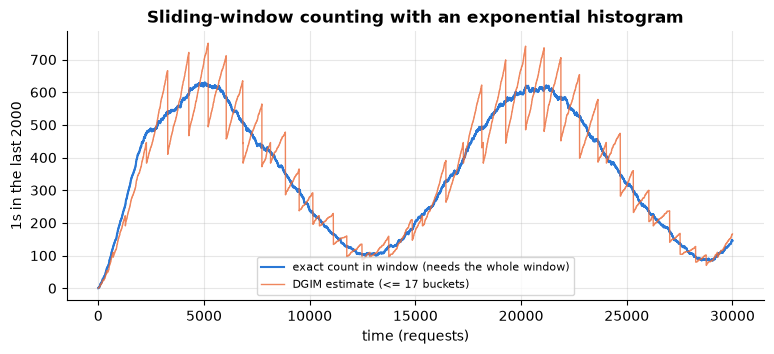

In [14]:
class DGIM:
    def __init__(self, window):
        self.W, self.t, self.buckets = window, 0, deque()   # buckets: (timestamp, size), newest on the right

    def add(self, bit):
        self.t += 1
        while self.buckets and self.buckets[0][0] <= self.t - self.W:
            self.buckets.popleft()                          # oldest bucket fell out of the window
        if bit:
            self.buckets.append((self.t, 1))
            size = 1
            while True:                                     # merge while 3 buckets share a size
                same = [i for i, (_, s) in enumerate(self.buckets) if s == size]
                if len(same) <= 2:
                    break
                i, j = same[0], same[1]                     # the two oldest of that size
                newest_ts = self.buckets[j][0]
                del self.buckets[j]; del self.buckets[i]
                self.buckets.insert(i, (newest_ts, 2 * size))
                size *= 2

    def estimate(self):
        if not self.buckets:
            return 0
        return sum(s for _, s in self.buckets) - self.buckets[0][1] / 2


rng = np.random.default_rng(4)
T, W = 30_000, 2_000
p_one = 0.05 + 0.25 * (np.sin(np.arange(T) / 2500) + 1) / 2         # error rate drifts over time
bits = (rng.random(T) < p_one).astype(int)
dg, window = DGIM(W), deque()
true_counts, est_counts, n_buckets, total = [], [], [], 0
for b in bits:
    dg.add(b)
    window.append(b); total += b
    if len(window) > W:
        total -= window.popleft()
    true_counts.append(total); est_counts.append(dg.estimate()); n_buckets.append(len(dg.buckets))
true_counts, est_counts = np.array(true_counts), np.array(est_counts)
rel = np.abs(est_counts - true_counts)[W:] / np.maximum(true_counts[W:], 1)
assert rel.max() <= 0.5
print(f"window W = {W}: max relative error = {rel.max():.3f}, mean = {rel.mean():.4f}, buckets kept <= {max(n_buckets)}")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(true_counts, label="exact count in window (needs the whole window)", lw=1.5)
ax.plot(est_counts, label=f"DGIM estimate (<= {max(n_buckets)} buckets)", lw=1, alpha=0.8)
ax.set(xlabel="time (requests)", ylabel=f"1s in the last {W}", title="Sliding-window counting with an exponential histogram")
ax.legend(fontsize=8); plt.show()

**What just happened?** Over 30,000 time steps the DGIM estimate tracked the exact window count while storing at most 17 buckets instead of 2,000 bits. The relative error never exceeded the 50% bound (maximum 38%, mean about 11%). If that is too coarse, allowing $r$ buckets per size instead of 2 shrinks the error to about $1/(r-1)$ for slightly more memory.

> 🎓 **Exam / interview tip:** sliding-window problems in interviews (max in window, count in window) usually allow $O(W)$ memory and are solved with a deque (see [`dsa/02`](../dsa/02_arrays_strings_and_techniques.ipynb)). DGIM is the answer when the follow-up is "and now with $O(\log^2 W)$ memory?".

---
## 9. Industry mini-case

> 💬 **In plain English:** two real jobs: removing duplicate training documents and counting unique users for a dashboard.

### 9.1 Deduplicating a fine-tuning corpus
A team collected 1,500 support answers to fine-tune a model. Many were copy-pasted with small edits. Near-duplicates waste compute, over-weight some answers, and increase **memorisation** (Lee et al., 2021, "Deduplicating Training Data Makes Language Models Better", found that removing near-duplicates reduced verbatim memorisation and train–test overlap). The pipeline: shingle → MinHash → LSH candidates → exact Jaccard check → **union-find clusters** → keep one document per cluster.

In [15]:
rng = np.random.default_rng(21)
corpus = build_corpus(1500, 300, rng)
for _ in range(60):                                   # some documents are copied several times (chains of edits)
    corpus.append(mutate(corpus[int(rng.integers(len(corpus)))], 0.05, rng))
S = [shingles(d) for d in corpus]

t0 = time.perf_counter()
pairs, n_cand = lsh_near_duplicates(S, threshold=0.5)
uf = UnionFind(len(S))
for i, j in pairs:
    uf.union(i, j)
clusters = defaultdict(list)
for i in range(len(S)):
    clusters[uf.find(i)].append(i)
keep = sorted(min(members) for members in clusters.values())   # keep one representative per cluster
t_pipeline = time.perf_counter() - t0

uf2 = UnionFind(len(S))
for i, j in exact_similar_pairs(S, 0.5):              # exact baseline: every pair scored
    uf2.union(i, j)
n_exact_clusters = len({uf2.find(i) for i in range(len(S))})
print(f"corpus: {len(S):,} documents")
print(f"LSH pipeline : {n_cand:,} candidate checks, kept {len(keep):,} documents ({len(S) - len(keep)} removed)")
print(f"exact pairs  : {len(S) * (len(S) - 1) // 2:,} pairs scored, kept {n_exact_clusters:,} documents")

corpus: 1,560 documents
LSH pipeline : 368 candidate checks, kept 1,245 documents (315 removed)
exact pairs  : 1,216,020 pairs scored, kept 1,242 documents


**What just happened?** The LSH pipeline kept almost exactly as many documents as the exact all-pairs method (a difference of a few documents, from near-duplicates just above the threshold that LSH missed), but checked only a few hundred candidate pairs instead of more than 1.2 million. (The exact baseline here is a vectorised sparse-matrix product; written as a Python loop over pairs it takes minutes even at this size.) On a real pre-training corpus (billions of documents) only the LSH route is feasible. Union-find matters: if A≈B and B≈C we want one cluster {A, B, C} even when A and C are less similar.

### 9.2 Unique users per day, per week, with HyperLogLog
A dashboard shows daily active users (DAU) and weekly active users (WAU). Each day's events are sketched once; the weekly number is a **merge**, never a sum.

In [16]:
rng = np.random.default_rng(22)
pool = rng.integers(0, 2**62, size=60_000, dtype=np.int64)        # all users of the product
days, daily_sets, daily_hll = 7, [], []
for day in range(days):
    active = rng.choice(pool, size=int(rng.integers(15_000, 25_000)), replace=False)   # who shows up today
    events = rng.choice(active, size=len(active) * 5)                                 # each user makes several events
    hll = HyperLogLog(p=12); hll.add(events)
    daily_sets.append(set(events.tolist())); daily_hll.append(hll)
rows = [{"day": d + 1, "exact DAU": len(s), "HLL DAU": round(h.count()), "error": f"{(h.count() - len(s)) / len(s):+.2%}"}
        for d, (s, h) in enumerate(zip(daily_sets, daily_hll))]
print(pd.DataFrame(rows).to_string(index=False))
week = HyperLogLog(p=12)
for h in daily_hll:
    week.merge(h)
exact_wau = len(set().union(*daily_sets))
print(f"\nexact WAU = {exact_wau:,} | merged HLL WAU = {week.count():,.0f} ({(week.count() - exact_wau) / exact_wau:+.2%})"
      f" | WRONG 'sum of DAUs' = {sum(len(s) for s in daily_sets):,}")
print(f"memory per day: HLL {week.m * 6 // 8:,} bytes vs a Python set of ids ~{sys.getsizeof(daily_sets[0]) / 1e6:.1f} MB")

 day  exact DAU  HLL DAU  error
   1      15298    15542 +1.60%
   2      15990    16268 +1.74%
   3      23209    23389 +0.77%
   4      19646    19463 -0.93%
   5      20468    20364 -0.51%
   6      18788    19000 +1.13%
   7      16727    16811 +0.50%

exact WAU = 55,622 | merged HLL WAU = 55,526 (-0.17%) | WRONG 'sum of DAUs' = 130,126
memory per day: HLL 3,072 bytes vs a Python set of ids ~0.5 MB


**What just happened?** Each daily HLL is within 2% of the exact DAU using 3 KB. The merged weekly HLL is within 0.2% of the exact WAU, while summing DAUs overcounts by a factor of more than 2 because most users come back on several days. The sketch is more than 100 times smaller than a Python set of the ids (and its size does not grow with the number of users).

---
## 10. Summary table

> 💬 **In plain English:** all the sketches side by side, and where AI systems use them.

| sketch | answers | error guarantee | memory | update | mergeable |
|---|---|---|---|---|---|
| reservoir sample (R) | uniform sample, any statistic of it | exact uniformity | $O(k)$ | $O(1)$ | yes (with weights) |
| Misra–Gries | heavy hitters, frequencies | under by $\le N/(k+1)$, deterministic | $O(k)$ | $O(1)$ amortised | yes |
| Space-Saving | top-$k$, frequencies | over by $\le N/k$, deterministic | $O(k)$ | $O(1)$ | yes (approx.) |
| Count-Min | frequency of any item | over by $\le \varepsilon N$ w.p. $1-\delta$ | $O(\frac1\varepsilon \log \frac1\delta)$ | $O(\log \frac1\delta)$ | yes (add) |
| HyperLogLog | number of distinct items | relative std. error $1.04/\sqrt m$ | $m$ registers of 6 bits | $O(1)$ | yes (max) |
| MinHash ($k$ hashes) | Jaccard similarity | std. error $\le 1/(2\sqrt k)$ | $O(k)$ per set | $O(k)$ per element | yes (min) |
| LSH banding | candidate similar pairs | S-curve $1-(1-s^r)^b$ | $O(nb)$ buckets | | |
| log-bucket (DDSketch) | quantiles | relative value error $\le \alpha$ | $O(\frac1\alpha \log \frac{\max}{\min})$ | $O(1)$ | yes (add) |
| KLL | quantiles | rank error $\le \varepsilon N$ w.h.p. | $O(\frac1\varepsilon \log\log\frac1\delta)$ (full KLL) | $O(1)$ amortised | yes |
| DGIM | count of 1s in last $W$ | relative error $\le 50\%$ ($r=2$) | $O(\log^2 W)$ bits | $O(\log W)$ | |
| Bloom filter ([`dsa/04`](../dsa/04_hashing.ipynb)) | membership | false positives only | ~10 bits/item for 1% | $O(k)$ | yes (OR) |

In [17]:
summary = pd.DataFrame(sorted(CHECKS.items()), columns=["guarantee checked", "items checked"])
print(summary.to_string(index=False))
print("all asserts passed (also: reservoir uniformity, weighted sampling, Count-Min bound and merge, DDSketch alpha, DGIM 50%)")

 guarantee checked  items checked
 Misra-Gries bound           9258
Space-Saving bound           9258
all asserts passed (also: reservoir uniformity, weighted sampling, Count-Min bound and merge, DDSketch alpha, DGIM 50%)


## 🔗 How this connects to modern AI

- **LLM pre-training data pipelines** deduplicate web-scale corpora with **MinHash-LSH** (near-duplicates) and **suffix arrays** (exact repeated substrings; see [notebook 08](08_advanced_data_structures.ipynb)). Lee et al. (2021) showed this reduces memorisation; most open pre-training datasets since then report a MinHash dedup step. See also [fine-tuning](../../08_LLM/03_fine_tuning/01_fine_tuning.ipynb) and [synthetic data](../../08_LLM/10_synthetic_data/01_synthetic_data.ipynb), where dedup of generated data matters too.
- **LSH for nearest-neighbour search**: random-hyperplane LSH (SimHash) for cosine similarity was an early approximate nearest-neighbour index for embeddings; modern vector databases mostly use graph indexes (HNSW) and IVF, compared in [vector databases](../../22_ML_System_Design/05_vector_databases.ipynb).
- **Feature pipelines and online learning**: Count-Min / the hashing trick for high-cardinality categorical features, HLL for "number of distinct devices per user in 24 h" fraud features ([fraud detection](../../03_Machine_Learning/08_anomaly_detection/02_industry_fraud_detection.ipynb), [streaming model updates](../../03_Machine_Learning/12_online_learning/02_industry_streaming_model_updates.ipynb), [feature stores](../../15_MLOps/12_feature_stores.ipynb)).
- **Monitoring ML and LLM services**: p95/p99 latency, tokens per request and drift statistics are computed from mergeable histograms and quantile sketches ([monitoring](../../15_MLOps/06_monitoring/01_monitoring.ipynb), [LLMOps](../../15_MLOps/13_llmops.ipynb)).
- **Reservoir sampling** keeps a uniform sample of production traffic for labelling, evaluation sets and replay buffers in continual learning; weighted versions implement importance sampling.
- **Data engineering**: Spark (`approx_count_distinct`), BigQuery, Druid, Redis and DuckDB (`approx_count_distinct`, `approx_quantile`) ship these sketches ([data engineering](../../13_Databases/06_data_engineering/01_data_engineering.ipynb), [DuckDB](../../02_Data_Analysis/10_duckdb.ipynb)).

## Recap
- Streaming = one pass, small memory, approximate answers with $(\varepsilon, \delta)$ guarantees; the best sketches are **mergeable**.
- **Reservoir sampling** keeps each item with probability $k/i$; prove it by induction.
- **Misra–Gries** (under-counts) and **Space-Saving** (over-counts) find heavy hitters with $k$ counters and a deterministic $N/k$ bound.
- **Count-Min**: $d$ hashed rows, take the minimum; error $\le \varepsilon N$ with $w = e/\varepsilon$, $d = \ln(1/\delta)$.
- **HyperLogLog**: leading zeros of hashes; error $1.04/\sqrt m$; merge by max; never add daily uniques.
- **MinHash** estimates Jaccard; **LSH banding** turns all-pairs into near-linear candidate generation with a tunable S-curve threshold.
- Quantiles: **log buckets** (relative value error) or **compactors/KLL** (rank error); merge sketches, never average p99s.
- **DGIM** counts in a sliding window with $O(\log^2 W)$ bits and at most 50% error.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** Why can't we answer "how many distinct items?" exactly with a Count-Min sketch, and why can't HyperLogLog tell us the frequency of one item?

<details><summary>Show solution</summary>

Count-Min stores sums of counts in hashed cells; it never records *which* items exist, and many distinct items share cells, so the number of distinct keys is lost. HyperLogLog keeps only the **maximum** rank per register, which duplicates do not change; that is exactly why it counts distinct items, and also why it has no information about how often any item occurred.

</details>

**2. (Easy, conceptual)** An HLL with $m = 2^{10}$ registers has standard error about 3.25%. How many registers do you need for about 0.8%? How much memory is that with 6-bit registers?

<details><summary>Show solution</summary>

Error $\propto 1/\sqrt m$: to divide the error by about 4 we need $16\times$ the registers, $m = 2^{14} = 16{,}384$ ($1.04/\sqrt{16384} = 0.81\%$). Memory $16{,}384 \times 6$ bits $= 12{,}288$ bytes = 12 KB.

</details>

**3. (Easy, coding)** Return a uniformly random line from a stream of unknown length using $O(1)$ memory.

<details><summary>Show solution</summary>

```python
import random
def sample_one_line(lines, rng=random):
    """Uniformly random line from an iterable in one pass, O(1) memory."""
    chosen = None
    for i, line in enumerate(lines, start=1):
        if rng.randrange(i) == 0:        # probability 1/i
            chosen = line
    return chosen
```
Tested with a chi-square test over 50,000 runs.

</details>

**4. (Medium, coding)** Write `cm_size(eps, delta)` that returns the Count-Min width and depth. What are they for $\varepsilon = 10^{-4}$, $\delta = 10^{-3}$?

<details><summary>Show solution</summary>

```python
import math
def cm_size(eps, delta):
    """Count-Min width and depth for error eps*N with probability 1 - delta."""
    return math.ceil(math.e / eps), math.ceil(math.log(1 / delta))
# e.g. eps = 0.0001, delta = 0.001  ->  (27183, 7): 190,281 counters, about 1.5 MB with 8-byte counters
```

</details>

**5. (Medium, coding)** Misra–Gries gives *candidates* but approximate counts. Using a **second pass**, return exactly the items with frequency $> N/(k+1)$.

<details><summary>Show solution</summary>

```python
from collections import Counter
def kth_frequent_candidates(stream, k):
    """Two passes: Misra-Gries with k counters to get candidates, then exact counts of those candidates only.
    Returns all items whose frequency is > N/(k+1)."""
    counters = {}
    n = 0
    for x in stream:                                 # pass 1: Misra-Gries
        n += 1
        if x in counters:
            counters[x] += 1
        elif len(counters) < k:
            counters[x] = 1
        else:
            for key in list(counters):
                counters[key] -= 1
                if counters[key] == 0:
                    del counters[key]
    exact = Counter(x for x in stream if x in counters)   # pass 2: count only the candidates
    return {x for x, c in exact.items() if c > n / (k + 1)}
```
Correct because every item with $f > N/(k+1)$ survives pass 1 (Section 3), and pass 2 counts candidates exactly. Tested against `Counter` on 200 random streams.

</details>

**6. (Medium, conceptual)** You use LSH with $b = 20$ bands of $r = 5$ rows. What is the probability that a pair with Jaccard 0.8 is **missed**? And that a pair with Jaccard 0.3 becomes a candidate?

<details><summary>Show solution</summary>

Candidate probability $1 - (1 - s^5)^{20}$. For $s = 0.8$: $0.8^5 = 0.328$, $(1 - 0.328)^{20} \approx 0.00036$, so it is missed with probability about **0.04%**. For $s = 0.3$: $0.3^5 = 0.00243$, $1 - (0.99757)^{20} \approx 0.047$, so about **4.7%** of such pairs become candidates (and are then rejected by the exact check).

</details>

**7. (Hard, coding/theory)** **SimHash** (random-hyperplane LSH) for cosine similarity: a random Gaussian vector $h$ gives the bit $\text{sign}(h \cdot x)$. Show empirically that two vectors at angle $\theta$ get the same bit with probability $1 - \theta/\pi$, and write the probability that `bits` independent bits all agree.

<details><summary>Show solution</summary>

```python
import numpy as np
def simhash_lsh_prob(theta, bits):
    """Probability that `bits` random-hyperplane signs all agree for two vectors at angle theta (radians)."""
    return (1 - theta / np.pi) ** bits
# Charikar (2002): one random hyperplane separates two vectors with probability theta / pi.
```
A random hyperplane through the origin separates $u$ and $v$ exactly when its normal falls in a wedge of angle $\theta$ out of $\pi$ (Charikar, 2002). Tested with 200,000 random hyperplanes for $\theta = 0.7$.

</details>

**8. (Hard, conceptual)** Prove that the Count-Min estimate never underestimates, and explain why the guarantee needs the hash rows to be *independent*.

<details><summary>Show solution</summary>

Every occurrence of $x$ increments $C[j, h_j(x)]$ in every row, and counters are only ever incremented (no deletions), so $C[j, h_j(x)] \ge f(x)$ for each $j$ and hence the minimum is $\ge f(x)$. For the upper bound we show each row exceeds $f(x) + \varepsilon N$ with probability $\le 1/e$ (Markov). The probability that **all** $d$ rows exceed it is $\le e^{-d}$ only if the rows' collision events are independent, which holds when each row uses an independently chosen hash function. With the same hash in every row all rows would fail together and extra rows would add nothing.

</details>

## Further reading (additional learning resources)
- Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets* (3rd ed.), ch. 3 (MinHash, LSH) and ch. 4 (reservoir-style sampling, DGIM, Flajolet–Martin): free at http://www.mmds.org
- Cormode & Yi, *Small Summaries for Big Data* (Cambridge, 2020): Count-Min, HLL, KLL, mergeability.
- Cormode & Muthukrishnan, "An improved data stream summary: the count-min sketch and its applications", *J. Algorithms* 2005.
- Flajolet, Fusy, Gandouet & Meunier, "HyperLogLog: the analysis of a near-optimal cardinality estimation algorithm", AofA 2007; Heule, Nunkesser & Hall, "HyperLogLog in Practice" (HLL++), EDBT 2013.
- Broder, "On the resemblance and containment of documents", 1997 (MinHash).
- Karnin, Lang & Liberty, "Optimal Quantile Approximation in Streams", FOCS 2016 (KLL); Masson, Rim & Lee, "DDSketch", VLDB 2019.
- Lee et al., "Deduplicating Training Data Makes Language Models Better", ACL 2022 (arXiv 2021).
- GeeksforGeeks: [Reservoir Sampling](https://www.geeksforgeeks.org/reservoir-sampling/), [Count-Min Sketch](https://www.geeksforgeeks.org/count-min-sketch-in-java-with-examples/).

## Next notebook
➡️ [07 · Computational geometry and FFT](07_computational_geometry_and_fft.ipynb): convex hulls, sweep lines, Voronoi diagrams, and the fast Fourier transform behind fast convolutions.